# 01 Cleaning & EDA

Loads `master.csv`, data quality summary, statistical tests, and business KPIs.
All heavy computation is pre-run by `src/clean.py` and `src/stats.py`.

In [1]:
import pandas as pd, json, warnings; warnings.filterwarnings('ignore')
master = pd.read_csv('../data/processed/master.csv')
print(f"Master table: {master.shape[0]:,} rows × {master.shape[1]} cols")
print(f"Date range: {master['date'].min()} to {master['date'].max()}")
print(f"Stores: {master['store_id'].nunique()} | Products: {master['product_id'].nunique()} | Categories: {master['category'].nunique()}")


Master table: 19,714 rows × 35 cols
Date range: 2026-05-01 to 2026-09-30
Stores: 5 | Products: 40 | Categories: 7


## Data Quality Summary

In [2]:
dq = pd.read_csv('../reports/data_quality.csv')
print(dq.to_string(index=False))


                        issue  count                                                action                                                            justification
        whitespace_casing_ids      5        Stripped whitespace and converted to uppercase            Inconsistent ID casing and whitespace cause false join misses
       duplicate_transactions   2482                                     Deduplicated rows                  Exact duplicate point-of-sale logs inflate sales volume
     category_casing_variants     10                     Mapped to standardized title case       Inconsistent casing/spelling fragments category-level aggregations
          negative_quantities    744   Flagged invalid_qty=1 and excluded from demand sums Negative/zero quantities represent returns/errors, not true sales demand
               missing_temp_c     15                              Imputed city-wise median               Missing sensor data filled with localized central tendency
              mi

## Statistical Tests

In [3]:
st = pd.read_csv('../reports/stats_tests.csv')
for _, r in st.iterrows():
    print(f"  {r['test']}: stat={r['statistic']:.2f}, p={r['p_value']:.2e} → {r['interpretation']}")


  Mann-Whitney U (one-sided): stat=30262008.00, p=0.00e+00 → Promotions generate a statistically significant increase in sales volume (p=0.0000e+00 < 0.05).
  Kruskal-Wallis H-test: stat=1854.34, p=0.00e+00 → Customer demand volume differs significantly across store formats (p=0.0000e+00 < 0.05).
  Chi-Square Test of Independence: stat=60.94, p=5.87e-15 → Promotions significantly increase stock-out probability due to demand spikes (p=5.8748e-15 < 0.05).


## Business KPIs

In [4]:
with open('../reports/kpis.json') as f: kpis = json.load(f)
for k, v in kpis.items():
    print(f"  {k}: {v}")


  revenue: 42284972.21
  units_sold: 397397
  stockout_rate: 0.0856
  inventory_turnover: 73.25
  days_of_inventory: 2.09
  promotion_lift: 1.3499
  estimated_lost_sales: 1446634.4


## EDA Figures (pre-saved)

01_category_pareto.png


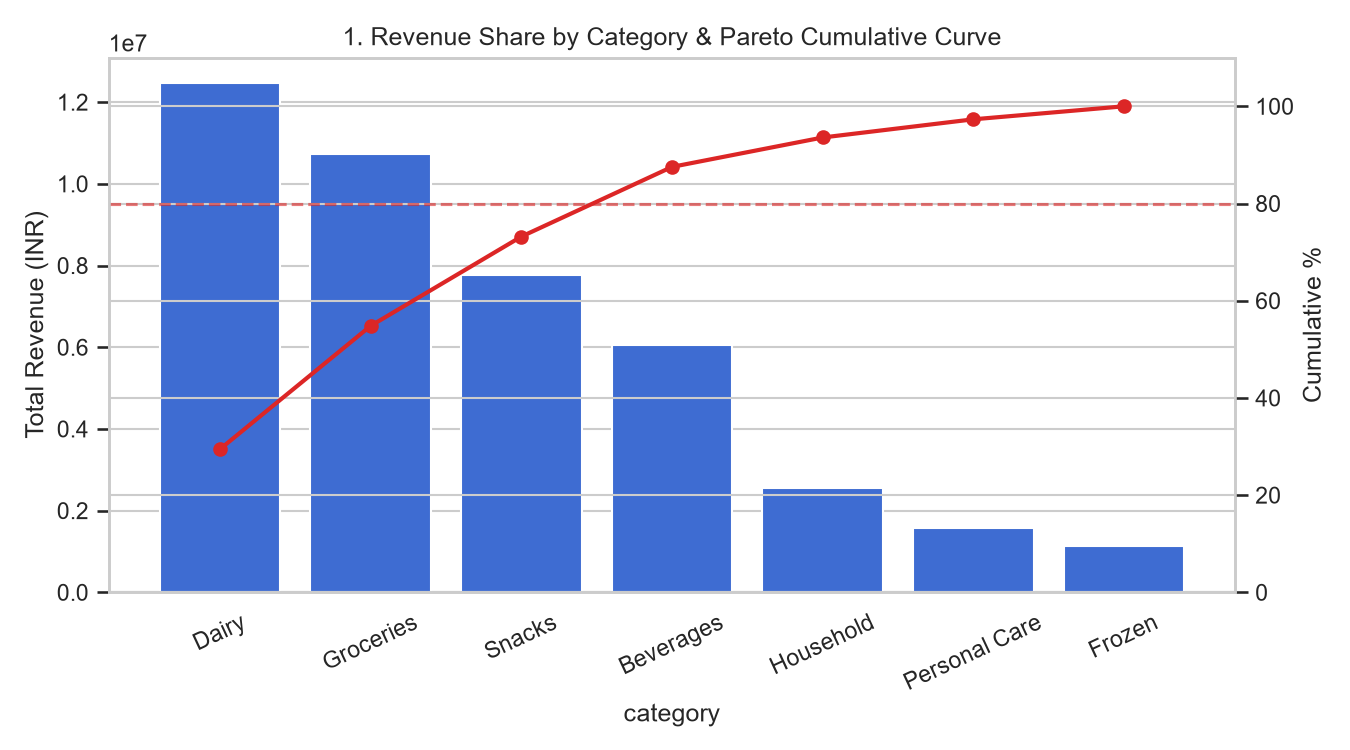

02_weekly_store_revenue.png


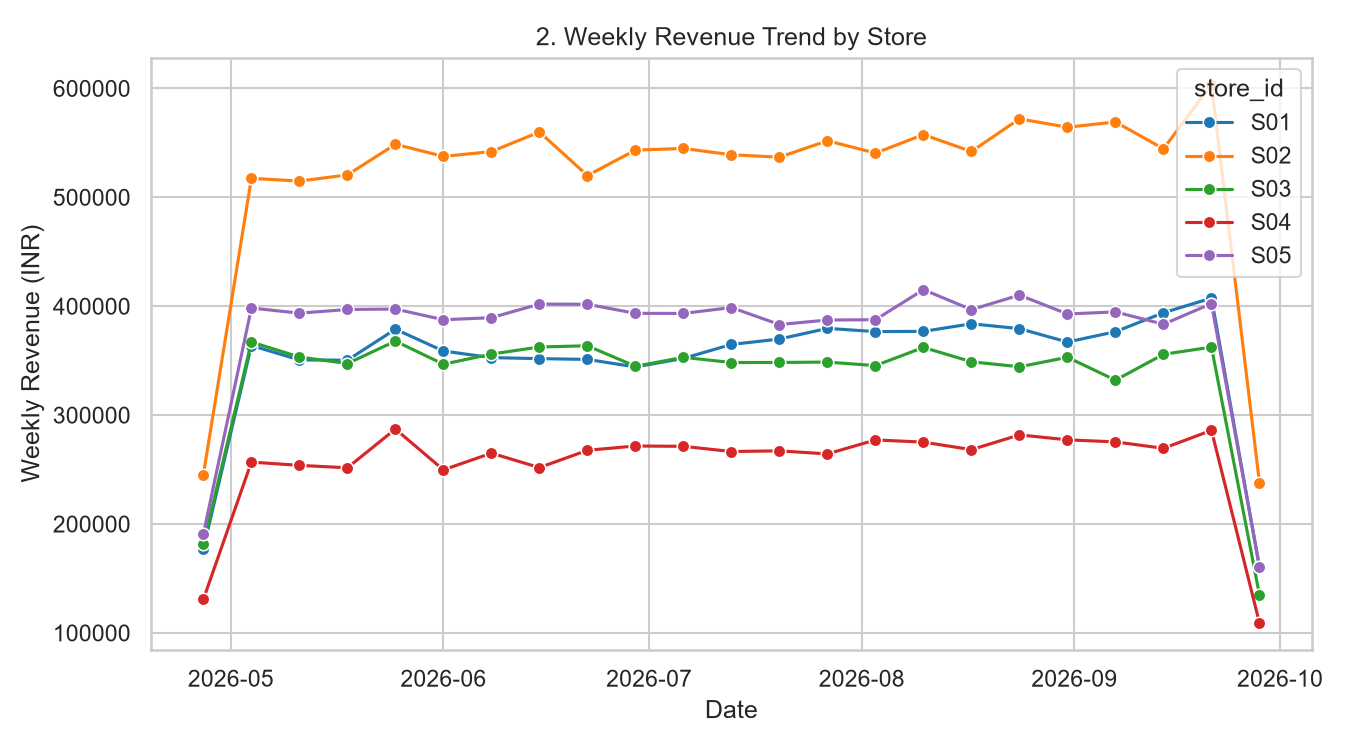

03_promo_vs_nonpromo.png


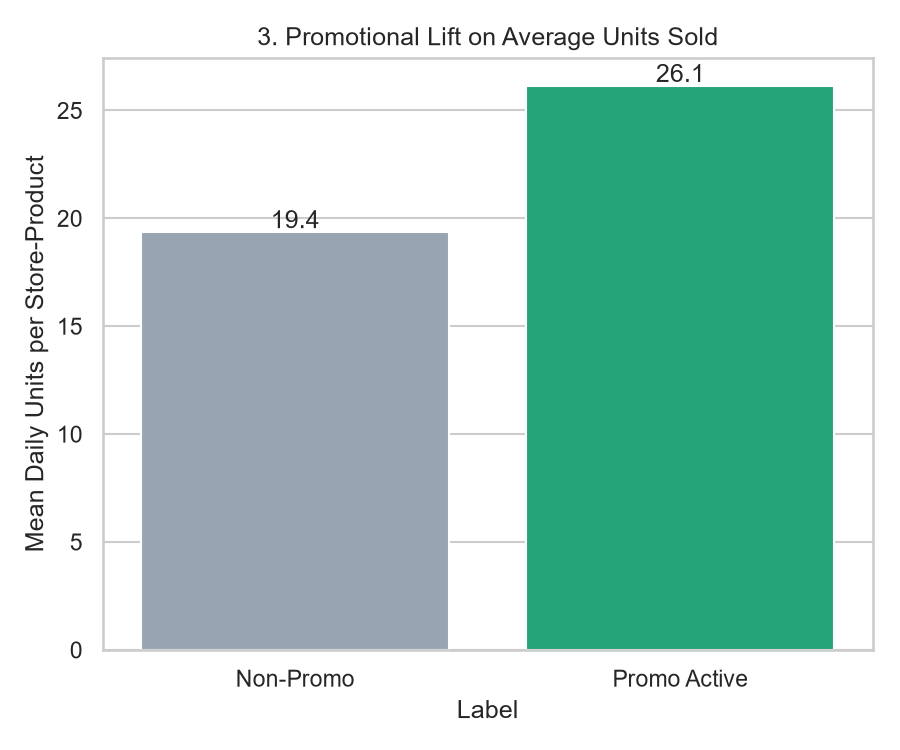

04_weekday_vs_weekend.png


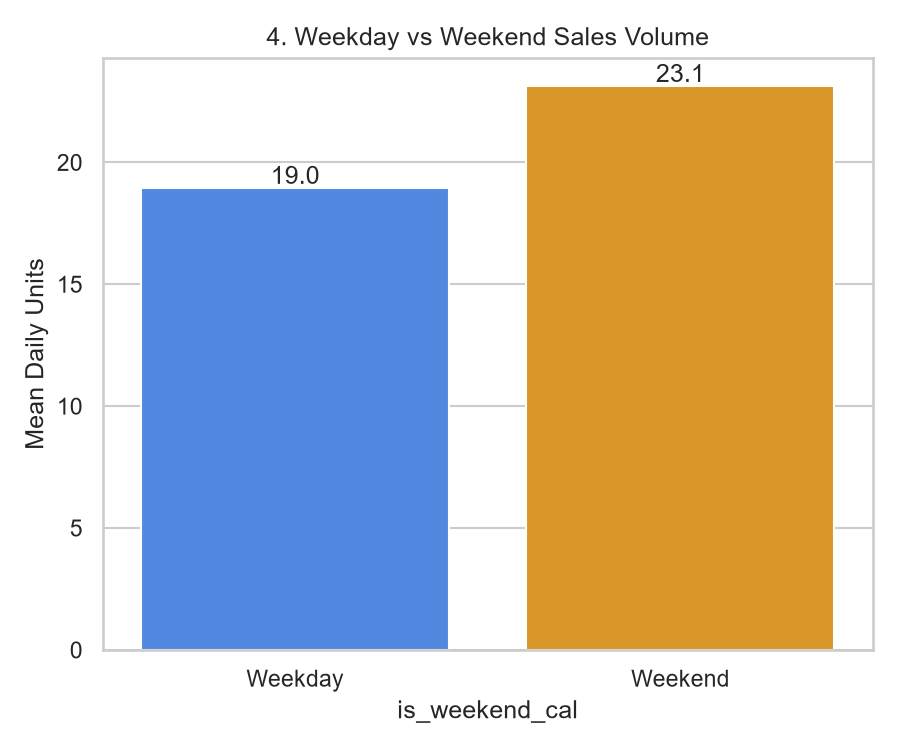

In [5]:
import os
from IPython.display import Image, display
fig_dir = '../reports/figures'
figs = sorted(os.listdir(fig_dir))[:4]
for fn in figs:
    print(fn)
    display(Image(os.path.join(fig_dir, fn), width=420))
